## Imports

In [1]:
import mne 
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
#import cv2

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

## Load EEG Data

In [2]:
# Load BrainVision data (.vhdr file) 
raw = mne.io.read_raw_brainvision(
    "../Data_EEG/901Goalie_Spring2024.vhdr",
    preload=True
)
 
# Access raw.info metadata 
info = raw.info 
print(info)

Extracting parameters from ../Data_EEG/901Goalie_Spring2024.vhdr...
Setting channel info structure...
Reading 0 ... 667389  =      0.000 ...  1334.778 secs...
<Info | 7 non-empty values
 bads: []
 ch_names: Fp1, Fz, F3, F7, FT9, FC5, FC1, C3, T7, Left Ear, CP5, CP1, Pz, ...
 chs: 63 EEG, 1 misc
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 140.0 Hz
 meas_date: 2024-03-13 09:47:23 UTC
 nchan: 64
 projs: []
 sfreq: 500.0 Hz
>


## Plotting the First 20 Seconds of the Raw Recording

Using matplotlib as 2D backend.


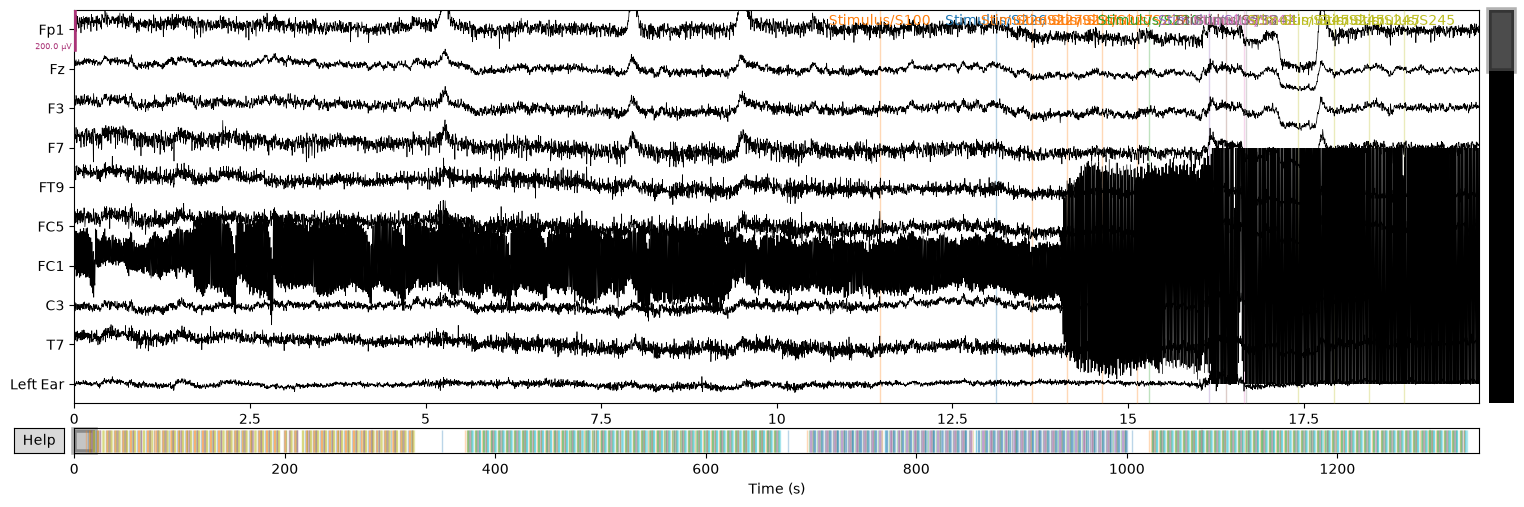

In [3]:
scaling_factor = 1e-4

fig = raw.plot(
    scalings=dict(eeg=scaling_factor),
    duration=20,
    n_channels=10,
    show=False
)

fig.set_size_inches(16, 5)
display(fig)
plt.close(fig)

## Visualizing the Event Markers

Used Annotations descriptions: [np.str_('New Segment/'), np.str_('Stimulus/S100'), np.str_('Stimulus/S101'), np.str_('Stimulus/S102'), np.str_('Stimulus/S105'), np.str_('Stimulus/S110'), np.str_('Stimulus/S113'), np.str_('Stimulus/S115'), np.str_('Stimulus/S117'), np.str_('Stimulus/S118'), np.str_('Stimulus/S126'), np.str_('Stimulus/S127'), np.str_('Stimulus/S130'), np.str_('Stimulus/S135'), np.str_('Stimulus/S138'), np.str_('Stimulus/S142'), np.str_('Stimulus/S144'), np.str_('Stimulus/S145'), np.str_('Stimulus/S151'), np.str_('Stimulus/S201'), np.str_('Stimulus/S202'), np.str_('Stimulus/S205'), np.str_('Stimulus/S210'), np.str_('Stimulus/S213'), np.str_('Stimulus/S215'), np.str_('Stimulus/S217'), np.str_('Stimulus/S218'), np.str_('Stimulus/S226'), np.str_('Stimulus/S227'), np.str_('Stimulus/S230'), np.str_('Stimulus/S235'), np.str_('Stimulus/S238'), np.str_('Stimulus/S242'), np.str_('Stimulus/S244'), np.str_('Stimulus/S245')]


[[  5732      0    100]
 [  6560      0    226]
 [  6814      0    227]
 ...
 [660846      0    145]
 [661098      0    145]
 [661350      0    145]]


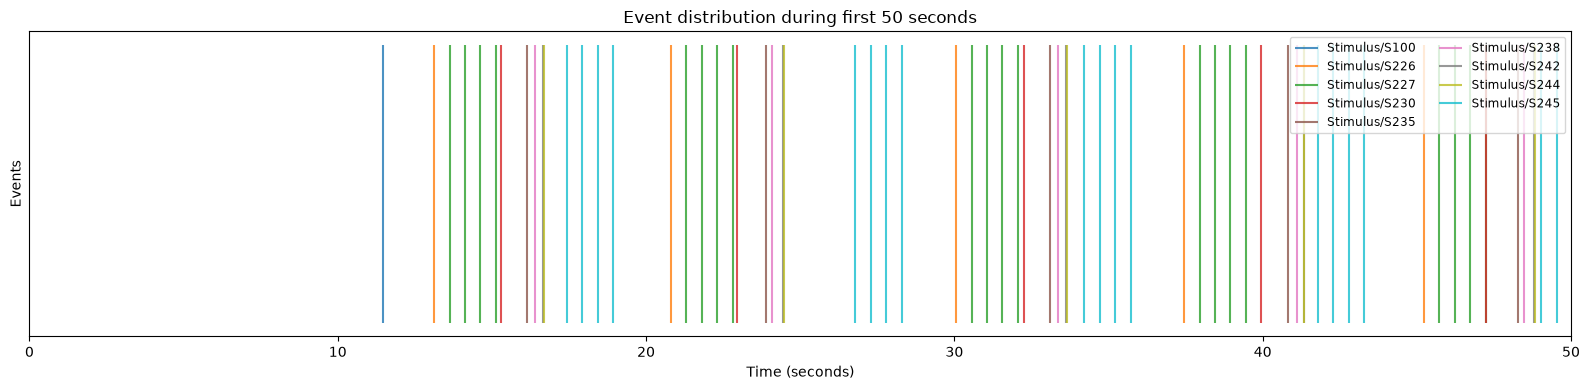

In [4]:
# Extract events and event IDs from annotations
events, event_id = mne.events_from_annotations(raw)
print(events)

# Map event IDs to descriptions
id_to_desc = {v: k for k, v in event_id.items()}

# Convert sample indices to seconds
times_sec = (events[:, 0] - raw.first_samp) / raw.info['sfreq']
event_ids = events[:, 2]

# Filter events for first 50 seconds
mask = (times_sec >= 0) & (times_sec <= 50)
times_50 = times_sec[mask]
event_ids_50 = event_ids[mask]

# Create figure
plt.figure(figsize=(16, 4))

# Get unique event IDs
unique_event_ids = sorted(set(event_ids_50))

# Use Matplotlib color cycle
colors = plt.get_cmap('tab10', max(len(unique_event_ids), 1))

# Plot each event as a vertical line
for i, event_id in enumerate(unique_event_ids):
    event_times = times_50[event_ids_50 == event_id]

    plt.vlines(
        event_times,
        ymin=0,
        ymax=1,
        color=colors(i),
        label=id_to_desc[event_id],
        alpha=0.8
    )

plt.xlabel('Time (seconds)')
plt.ylabel('Events')
plt.title('Event distribution during first 50 seconds')
plt.xlim(0, 50)
plt.yticks([])
if len(unique_event_ids) > 0:
    plt.legend(loc='upper right', fontsize='small', ncol=2)
plt.tight_layout()
plt.show()


## Pre-processing

### Drop Channels 'Corr' and 'Left Ear'

In [5]:
print(f"Initial channel count: {raw.info['nchan']}")

chs_to_remove = ['Corr','Left Ear']
raw.drop_channels(chs_to_remove, on_missing='raise')

print(f"Final channel count: {raw.info['nchan']}")

Initial channel count: 64
Final channel count: 62


### Compute and Plot PSD of Raw EEG

Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).


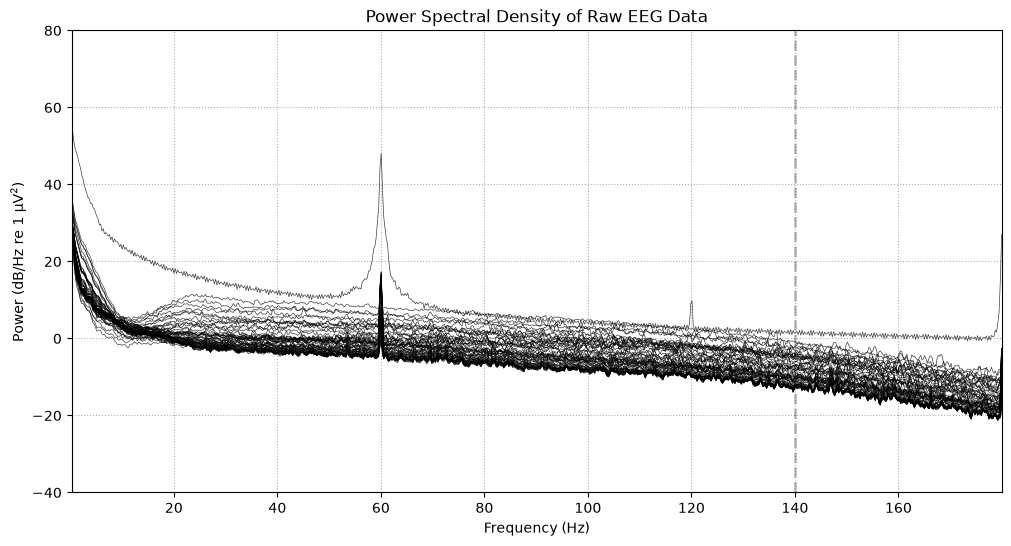

In [6]:
# Compute PSD
psd = raw.compute_psd(fmin=0.05, fmax=180, picks='eeg')

# Plot the PSD
fig, ax = plt.subplots(figsize=(12, 6))
psd.plot(axes=ax, spatial_colors=False)
ax.set_ylim([-40, 80])
ax.set_title('Power Spectral Density of Raw EEG Data')
plt.show()

### Apply Band-pass Filter and Plot PSD 

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.1 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation


- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 16501 samples (33.002 s)

Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).


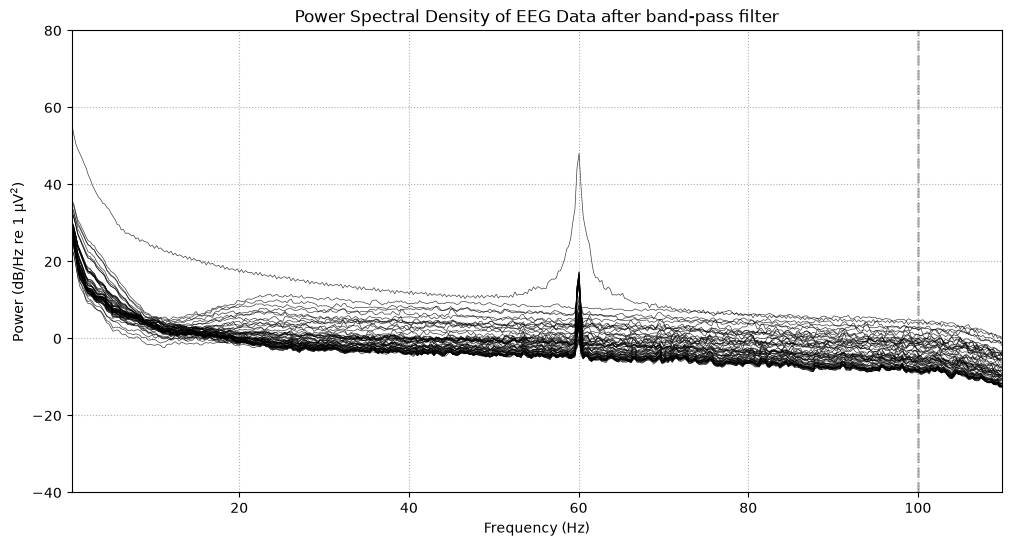

In [7]:
raw.filter(l_freq=0.1, h_freq=100)

# Compute PSD after band-pass filter
psd = raw.compute_psd(fmin=0.05, fmax=110, picks='eeg')

# Plot the PSD after band-pass filter
fig, ax = plt.subplots(figsize=(12, 6))
psd.plot(axes=ax, spatial_colors=False)
ax.set_ylim([-40, 80])
ax.set_title('Power Spectral Density of EEG Data after band-pass filter')
plt.show()

### Apply Notch Filter and Plot PSD After Filtration

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 59 - 61 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 59.35
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 59.10 Hz)
- Upper passband edge: 60.65 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 60.90 Hz)


- Filter length: 3301 samples (6.602 s)

Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).


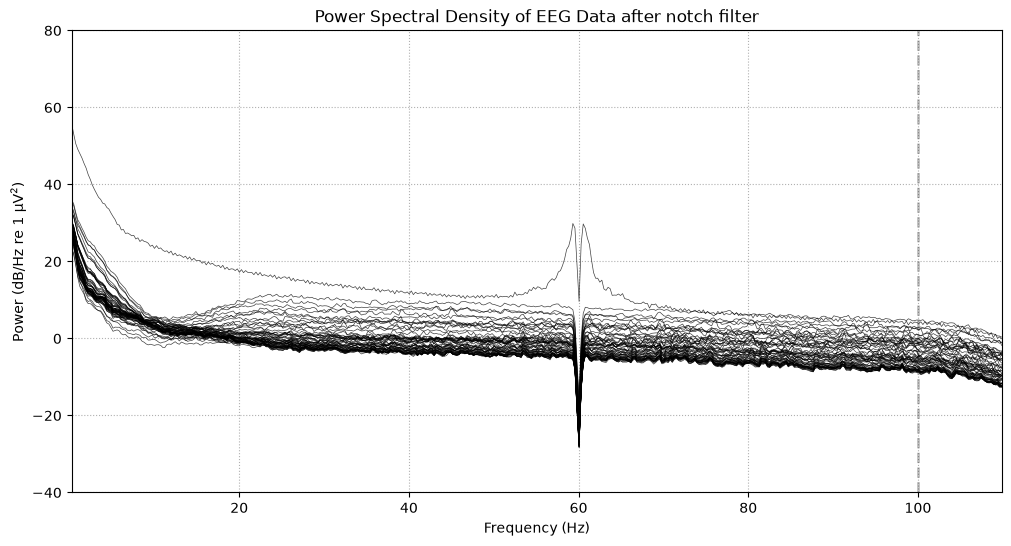

In [8]:
raw.notch_filter(freqs = 60)

# Compute PSD after notch filter
psd = raw.compute_psd(fmin=0.05, fmax=110, picks='eeg')

# Plot the PSD after notch filter
fig, ax = plt.subplots(figsize=(12, 6))
psd.plot(axes=ax, spatial_colors=False)
ax.set_ylim([-40, 80])
ax.set_title('Power Spectral Density of EEG Data after notch filter')
plt.show()

### Resampling

In [9]:
raw.resample(sfreq=250)

<RawBrainVision | 901Goalie_Spring2024.eeg, 62 x 333695 (1334.8 s), ~157.9 MiB, data loaded>

## Plotting the First 20 Seconds of the Pre-Processed Recording

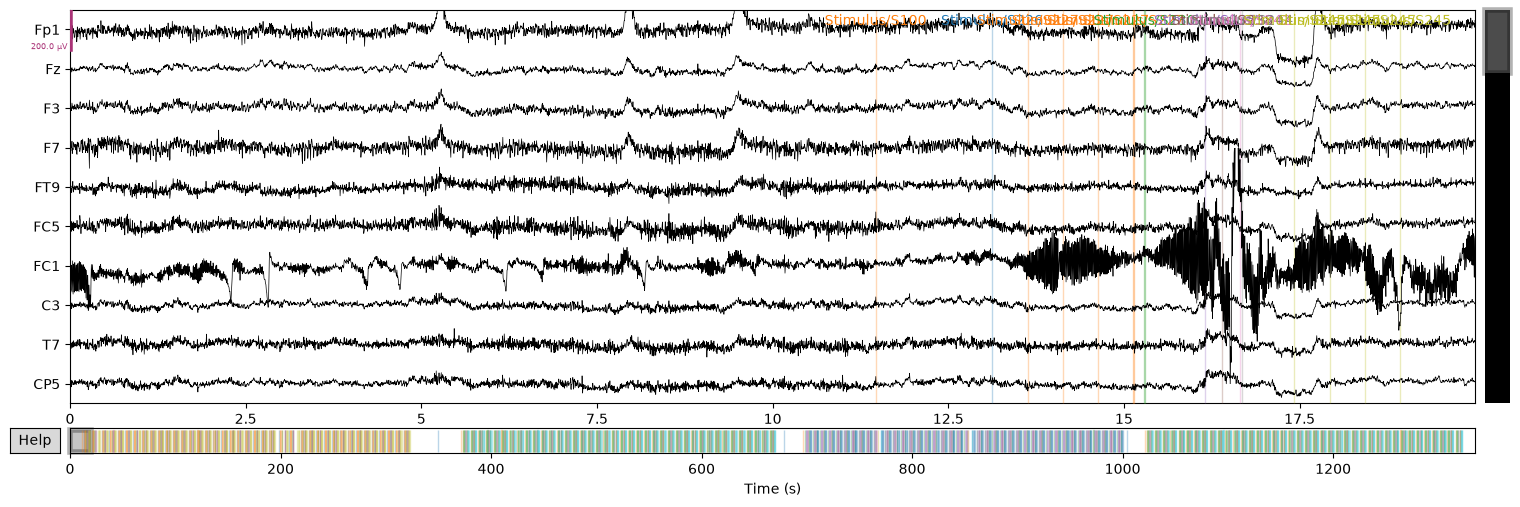

In [10]:
scaling_factor = 1e-4

fig = raw.plot(
    scalings=dict(eeg=scaling_factor),
    duration=20,
    n_channels=10,
    show=False
)

fig.set_size_inches(16, 5)
display(fig)
plt.close(fig)

## Extracting ERP signals


### Functions for ERP Extraction

In [11]:
# Extract All Trials from Start Codes to End Codes
def extract_events(raw, start_code=230, end_code=245, peristimulus=0.5):
    events, event_id = mne.events_from_annotations(raw)
    start_indices = np.where(events[:, 2] == start_code)[0]
    end_indices = np.where(events[:, 2] == end_code)[0]
    extracted_events = []
    sfreq = raw.info['sfreq']
    peristimulus_samples = int(peristimulus * sfreq)

    for start_idx in start_indices:
        end_idx = end_indices[end_indices > start_idx]
        if len(end_idx) == 0:
            continue
        end_idx = end_idx[0]
        start_sample = max(0, events[start_idx, 0] - peristimulus_samples)
        end_sample = events[end_idx, 0]
        extracted_events.append((start_sample, end_sample))

    return extracted_events



# Categorize Trials to Left and Right (Excluding Bad Trials)
def categorize_trials(extracted_events, csv_path):
    trial_info = pd.read_csv(csv_path)
    good_trials = trial_info['GoodTrial'].values
    trial_types = trial_info['TrialType'].values

    left_trials, right_trials = [], []
    left_lengths, right_lengths = [], []

    for i, (start, end) in enumerate(extracted_events):
        length = end - start
        if good_trials[i] == 1:
            if trial_types[i] == 'left':
                left_trials.append((start, end))
                left_lengths.append(length)
            elif trial_types[i] == 'right':
                right_trials.append((start, end))
                right_lengths.append(length)
    
    # Print Lengths Before Padding
    print(f"Number of left trials: {len(left_trials)}, Avg Length: {np.mean(left_lengths) if left_lengths else 'N/A'} samples")
    print(f"Number of right trials: {len(right_trials)}, Avg Length: {np.mean(right_lengths) if right_lengths else 'N/A'} samples")
    
    print(f"Max Length of left trials: {max(left_lengths) if left_lengths else 'N/A'} samples")
    print(f"Min Length of left trials: {min(left_lengths) if left_lengths else 'N/A'} samples")
    
    print(f"Max Length of right trials: {max(right_lengths) if right_lengths else 'N/A'} samples")
    print(f"Min Length of right trials: {min(right_lengths) if right_lengths else 'N/A'} samples")
    
    # Print overall maximum length
    all_lengths = left_lengths + right_lengths
    if all_lengths:
        print(f"Overall maximum trial length: {max(all_lengths)} samples")
    
    return left_trials, right_trials


# Padding
def pad_events(raw, left_trials, right_trials, verbose=True):
    all_trials = left_trials + right_trials
    max_length = max([end - start for start, end in all_trials])

    left_padded, right_padded = [], []

    for start, end in left_trials:
        event_data = raw.get_data(start=start, stop=end)
        padded_event = np.full((event_data.shape[0], max_length), np.nan)
        padded_event[:, :event_data.shape[1]] = event_data
        left_padded.append(padded_event)

    for start, end in right_trials:
        event_data = raw.get_data(start=start, stop=end)
        padded_event = np.full((event_data.shape[0], max_length), np.nan)
        padded_event[:, :event_data.shape[1]] = event_data
        right_padded.append(padded_event)

    left_padded = np.array(left_padded)
    right_padded = np.array(right_padded)
    if verbose:
        print(f"Final length of left events (samples): {left_padded.shape[2]}")
        print(f"Final length of right events (samples): {right_padded.shape[2]}")
    return left_padded, right_padded


# Averaging Left and Right Trials Seperatley
def calculate_averages(left_data, right_data):
    
    # Average across trials (axis 0)
    left_avg = np.nanmean(left_data, axis=0)
    right_avg = np.nanmean(right_data, axis=0)
    
    print(f"Left ERP shape: {left_avg.shape}")
    print(f"Right ERP shape: {right_avg.shape}")
    
    return left_avg, right_avg


# Plot ERPs
def plot_erps(left_padded, right_padded, left_avg, right_avg, sfreq, channel_idx=None, peristimulus=0.5):
   
    # Create time vector adjusted for peristimulus period
    time = np.arange(left_avg.shape[1]) / sfreq - peristimulus
    
    plt.figure(figsize=(12, 6))
    
    if channel_idx is not None:
        # Plot specific channel
        # Calculate SEM across trials for this channel
        left_sem = np.nanstd(left_padded[:, channel_idx, :], axis=0) / np.sqrt(left_padded.shape[0])
        right_sem = np.nanstd(right_padded[:, channel_idx, :], axis=0) / np.sqrt(right_padded.shape[0])
        
        plt.plot(time, left_avg[channel_idx], label='Left', color='blue')
        plt.fill_between(time, left_avg[channel_idx] - left_sem, 
                         left_avg[channel_idx] + left_sem, alpha=0.3, color='blue')
        
        plt.plot(time, right_avg[channel_idx], label='Right', color='red')
        plt.fill_between(time, right_avg[channel_idx] - right_sem, 
                         right_avg[channel_idx] + right_sem, alpha=0.3, color='red')
        
        plt.title(f'ERP for Left and Right Trials - Channel {channel_idx}')
    else:
        # Average across all channels
        channel_avg_left = np.mean(left_avg, axis=0)
        channel_avg_right = np.mean(right_avg, axis=0)
        
        # First average over trials for each channel, then average across channels
        # For SEM, first average over trials for each channel, then calculate SEM across channels
        # This gives us channel-to-channel variability in the average response
        
        # Standard error of the mean across channels (across-channel variability)
        n_channels = left_avg.shape[0]
        left_sem = np.std(left_avg, axis=0) / np.sqrt(n_channels)
        right_sem = np.std(right_avg, axis=0) / np.sqrt(n_channels)
        
        plt.plot(time, channel_avg_left, label='Left', color='blue')
        plt.fill_between(time, channel_avg_left - left_sem, 
                         channel_avg_left + left_sem, alpha=0.3, color='blue')
        
        plt.plot(time, channel_avg_right, label='Right', color='red')
        plt.fill_between(time, channel_avg_right - right_sem, 
                         channel_avg_right + right_sem, alpha=0.3, color='red')
        
        plt.title('ERP for Left and Right Trials (Averaged Across Channels)')
    
    # Add stimulus onset line
    plt.axvline(x=0, color='k', linestyle='--', alpha=0.5, label='Stimulus Onset')
    
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude (µV)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Applying the Functions

In [13]:
warnings.filterwarnings("ignore", category=RuntimeWarning)
events = extract_events(raw, start_code=230, end_code=245, peristimulus=0.5)
print(f'Number of extracted events : {len(events)}') # events is a list of all the trial samples

left_trials, right_trials = categorize_trials(events, '../Data_EEG/TrialInfo.csv')

left_padded, right_padded = pad_events(raw, left_trials, right_trials)
print(left_padded.shape)
print(right_padded.shape)

left_avg, right_avg = calculate_averages(left_padded, right_padded)

Used Annotations descriptions: [np.str_('New Segment/'), np.str_('Stimulus/S100'), np.str_('Stimulus/S101'), np.str_('Stimulus/S102'), np.str_('Stimulus/S105'), np.str_('Stimulus/S110'), np.str_('Stimulus/S113'), np.str_('Stimulus/S115'), np.str_('Stimulus/S117'), np.str_('Stimulus/S118'), np.str_('Stimulus/S126'), np.str_('Stimulus/S127'), np.str_('Stimulus/S130'), np.str_('Stimulus/S135'), np.str_('Stimulus/S138'), np.str_('Stimulus/S142'), np.str_('Stimulus/S144'), np.str_('Stimulus/S145'), np.str_('Stimulus/S151'), np.str_('Stimulus/S201'), np.str_('Stimulus/S202'), np.str_('Stimulus/S205'), np.str_('Stimulus/S210'), np.str_('Stimulus/S213'), np.str_('Stimulus/S215'), np.str_('Stimulus/S217'), np.str_('Stimulus/S218'), np.str_('Stimulus/S226'), np.str_('Stimulus/S227'), np.str_('Stimulus/S230'), np.str_('Stimulus/S235'), np.str_('Stimulus/S238'), np.str_('Stimulus/S242'), np.str_('Stimulus/S244'), np.str_('Stimulus/S245')]
Number of extracted events : 40
Number of left trials: 17, 

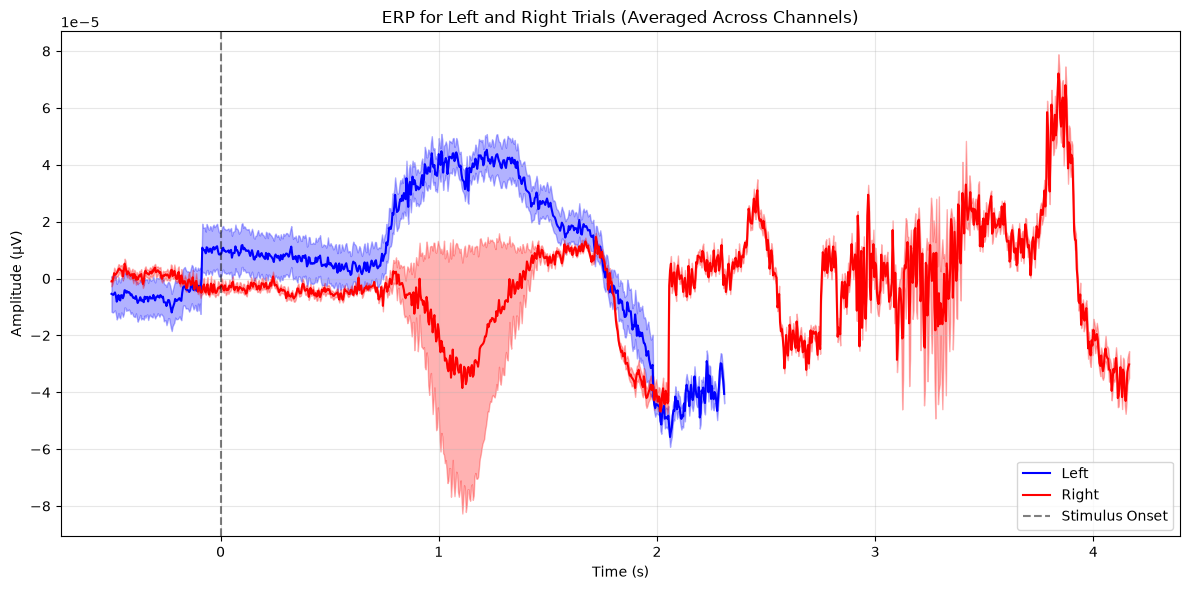

In [14]:
plot_erps(left_padded, right_padded, left_avg, right_avg, raw.info['sfreq'], channel_idx=None, peristimulus=0.5)

## Create Topographic Maps 

## Applying standard Montage

4 duplicate electrode labels found:
T7/T3, T8/T4, P7/T5, P8/T6
Plotting 90 unique labels.


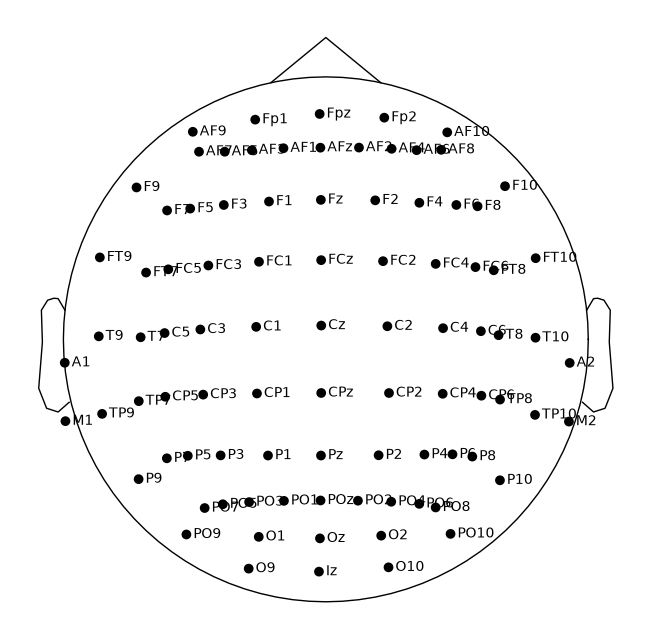

In [15]:
montage = mne.channels.make_standard_montage('standard_1020') # load standard montage from mne

positions = montage.get_positions()['ch_pos']

shift = np.array([-0.003, 0.017, 0.06])

shifted_positions = {ch: pos + shift for ch, pos in positions.items()}

costum_montage = mne.channels.make_dig_montage(ch_pos = shifted_positions, coord_frame='head')

raw.set_montage(costum_montage)

mne.viz.plot_montage(costum_montage, show_names = True)
plt.show()

### Calculate Frame Indices and Time Points

In [16]:
def calculate_timepoints(n_samples, sfreq, video_duration, fps):
    total_frames = video_duration * fps
    step = (n_samples // total_frames) + 1
    
    # Ensure the frame indices do not exceed the sample count
    frame_indices = np.arange(0, n_samples, step)
    time_points = (frame_indices / sfreq) - 0.5
    
    print(f"Calculated time step per frame: {step} samples")
    print(f"Number of frames: {len(frame_indices)}")
    print(f"Time range: {time_points[0]:.2f} s to {time_points[-1]:.2f} s")
    
    return frame_indices, time_points
    
sfreq = raw.info['sfreq']
frame_indices, time_points = calculate_timepoints(563, sfreq, video_duration=15, fps=10)


Calculated time step per frame: 4 samples
Number of frames: 141
Time range: -0.50 s to 1.74 s


## Generate Topo-Map Frames

In [17]:
def create_topomap_frames(raw, left_avg, right_avg, frame_indices, time_points, output_dir, vlim=(-1e-4, 1e-4)):
    os.makedirs(output_dir, exist_ok=True)
    info = raw.info

    for idx, i in enumerate(frame_indices):
        fig, axes = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={'width_ratios': [1, 1, 1.2]})
        plt.suptitle(f"Time: {time_points[idx]:.2f} s")

        # Left ERP Topomap
        im, _ = mne.viz.plot_topomap(left_avg[:, i], info, axes=axes[0], names=info.ch_names, show=False, vlim=vlim)
        mne.viz.utils.plot_sensors(info, axes=axes[0], show_names=True, show=False)
        axes[0].set_title("Left Trials")
        cbar = plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
        cbar.set_label('Amplitude (µV)')

        # Right ERP Topomap
        im, _ = mne.viz.plot_topomap(right_avg[:, i], info, axes=axes[1], names=info.ch_names, show=False, vlim=vlim)
        mne.viz.utils.plot_sensors(info, axes=axes[1], show_names=True, show=False)
        axes[1].set_title("Right Trials")
        cbar = plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
        cbar.set_label('Amplitude (µV)')

        # ERP Plot with Left and Right Separately
        time_vector = np.arange(left_avg.shape[1]) / raw.info['sfreq'] - 0.5

        # Calculate SEM
        left_sem = np.nanstd(left_avg, axis=0) / np.sqrt(left_avg.shape[0])
        right_sem = np.nanstd(right_avg, axis=0) / np.sqrt(right_avg.shape[0])

        # Plot Left ERP with SEM
        axes[2].plot(time_vector, np.nanmean(left_avg, axis=0), label='Left', color='blue')
        axes[2].fill_between(time_vector, 
                             np.nanmean(left_avg, axis=0) - left_sem, 
                             np.nanmean(left_avg, axis=0) + left_sem, 
                             color='blue', alpha=0.3)

        # Plot Right ERP with SEM
        axes[2].plot(time_vector, np.nanmean(right_avg, axis=0), label='Right', color='red')
        axes[2].fill_between(time_vector, 
                             np.nanmean(right_avg, axis=0) - right_sem, 
                             np.nanmean(right_avg, axis=0) + right_sem, 
                             color='red', alpha=0.3)

        # Add fixed time marker at 0s
        axes[2].axvline(x=0, color='gray', linestyle='--', alpha=0.7, label='Stimulus Onset')

        # Add moving time marker
        axes[2].axvline(x=time_points[idx], color='black', linestyle='--')

        axes[2].set_title("ERP with Time Marker")
        axes[2].set_xlabel("Time (s)")
        axes[2].set_ylabel("Amplitude (µV)")
        axes[2].legend()

        plt.tight_layout()
        frame_path = os.path.join(output_dir, f"frame_{idx:04d}.png")
        plt.savefig(frame_path)
        plt.close()

In [18]:
left_avg = left_avg[:, :frame_indices[-1]+1]
right_avg = right_avg[:, :frame_indices[-1]+1]

output_dir = "frames0"
vlim = (-1e-4, 1e-4)
create_topomap_frames(raw, left_avg, right_avg, frame_indices, time_points, output_dir, vlim)

### 4.4 Compile Video

In [20]:
import cv2

def compile_video(output_dir, video_path, fps):
    frames = sorted([f for f in os.listdir(output_dir) if f.endswith('.png')])
    if not frames:
        print("No frames found in the specified directory.")
        return

    frame_path = os.path.join(output_dir, frames[0])
    frame = cv2.imread(frame_path)
    height, width, _ = frame.shape

    video = cv2.VideoWriter(video_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (width, height))

    for frame_name in frames:
        frame_path = os.path.join(output_dir, frame_name)
        frame = cv2.imread(frame_path)
        video.write(frame)

    video.release()
    print(f"Video saved as {video_path}")

In [21]:
video_path =  "901Goalie_Spring2024_Before.mp4"
compile_video(output_dir, video_path, fps=10)

Video saved as 901Goalie_Spring2024_Before.mp4


## Identifying and Handling Bad Channels

## Add FC1 to Bad Channels and Interpolate 

In [22]:
raw.info['bads'] = ['FC1']
print(f"Bad channels : {raw.info['bads']}")
raw.interpolate_bads(reset_bads = True)

Bad channels : ['FC1']
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 96.2 mm
Computing interpolation matrix from 61 sensor positions
Interpolating 1 sensors


<RawBrainVision | 901Goalie_Spring2024.eeg, 62 x 333695 (1334.8 s), ~157.9 MiB, data loaded>

### Extracting ERP Signals After Interpolation of Bad Channel

In [23]:
events = extract_events(raw, start_code=230, end_code=245, peristimulus=0.5)

print(f'Number of extracted events : {len(events)}')

left_trials, right_trials = categorize_trials(events, '../Data_EEG/TrialInfo.csv')

left_padded, right_padded = pad_events(raw, left_trials, right_trials)

left_avg, right_avg = calculate_averages(left_padded, right_padded)

Used Annotations descriptions: [np.str_('New Segment/'), np.str_('Stimulus/S100'), np.str_('Stimulus/S101'), np.str_('Stimulus/S102'), np.str_('Stimulus/S105'), np.str_('Stimulus/S110'), np.str_('Stimulus/S113'), np.str_('Stimulus/S115'), np.str_('Stimulus/S117'), np.str_('Stimulus/S118'), np.str_('Stimulus/S126'), np.str_('Stimulus/S127'), np.str_('Stimulus/S130'), np.str_('Stimulus/S135'), np.str_('Stimulus/S138'), np.str_('Stimulus/S142'), np.str_('Stimulus/S144'), np.str_('Stimulus/S145'), np.str_('Stimulus/S151'), np.str_('Stimulus/S201'), np.str_('Stimulus/S202'), np.str_('Stimulus/S205'), np.str_('Stimulus/S210'), np.str_('Stimulus/S213'), np.str_('Stimulus/S215'), np.str_('Stimulus/S217'), np.str_('Stimulus/S218'), np.str_('Stimulus/S226'), np.str_('Stimulus/S227'), np.str_('Stimulus/S230'), np.str_('Stimulus/S235'), np.str_('Stimulus/S238'), np.str_('Stimulus/S242'), np.str_('Stimulus/S244'), np.str_('Stimulus/S245')]
Number of extracted events : 40
Number of left trials: 17, 

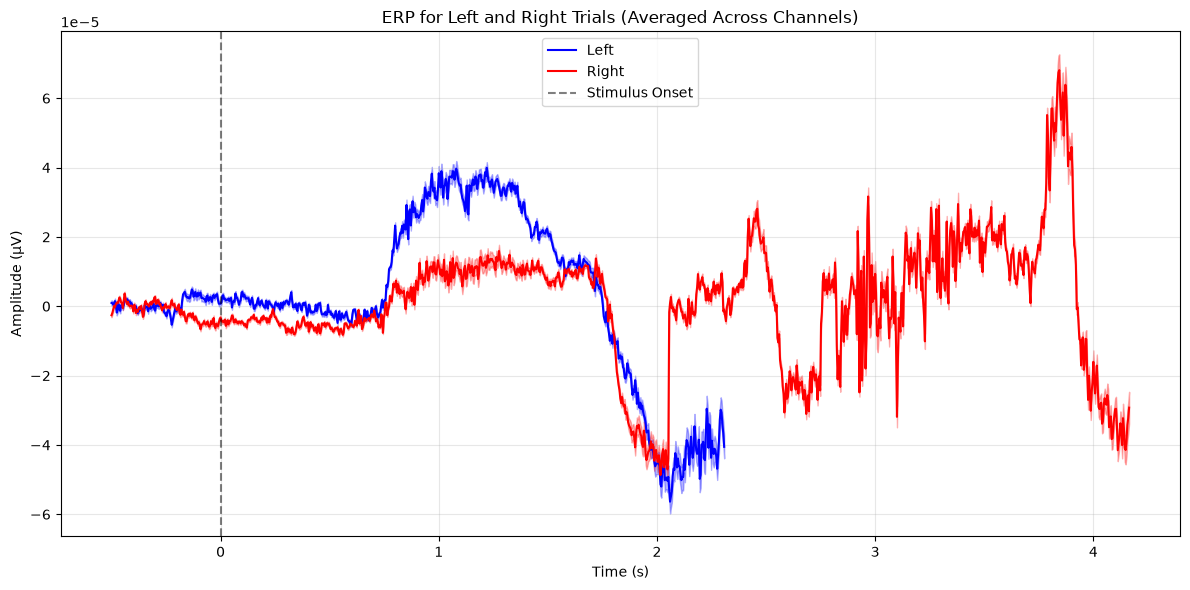

In [24]:
plot_erps(left_padded, right_padded, left_avg, right_avg, raw.info['sfreq'], channel_idx=None, peristimulus=0.5)

### 5.3 Create video After Interpolation of Bad Channel

In [25]:
left_avg = left_avg[:, :frame_indices[-1]+1]
right_avg = right_avg[:, :frame_indices[-1]+1]

output_dir = "frames1"
vlim = (-1e-4, 1e-4)
create_topomap_frames(raw, left_avg, right_avg, frame_indices, time_points, output_dir, vlim)

In [26]:
video_path = "901Goalie_Spring2024_After.mp4"
compile_video(output_dir, video_path, fps=10)

Video saved as 901Goalie_Spring2024_After.mp4
